# Semantic verbal fluency and left inferior parietal thickness
### Phase 5 final synthesis · Track C (NACC)

How many more or fewer animals do people with normal cognition name in 60 seconds for each 0.1 mm of greater left inferior parietal thickness, after accounting for age, recorded sex and education? Here we bring together the five phases and rebuild their evidence from the local course data and the registered analyses.

In [1]:
from io import BytesIO
from pathlib import Path
import os
import sys

from IPython.display import Image, Markdown, display

root = Path.cwd()
if root.name == "notebooks" and (root.parent / "src").is_dir():
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))

from src.phase5_summary import REPORT_FILE, build_figures, build_synthesis, compare, read_json

results = build_synthesis()
compare(read_json(REPORT_FILE), results, "Final synthesis")

DESCRIPTIVE_HEADERS = ('Cognitive status', 'Total', 'Score n', 'Score mean ± SD', 'MRI n', 'Left mm mean ± SD')
GROUP_LABELS = ('Normal cognition', 'Impaired without MCI', 'MCI', 'Dementia')
TWO_HEADERS = ('Measure', 'Value')
PROBABILITY_LABELS = ('Normal cognition at or above the cutoff', 'Normal cognition below the cutoff', 'At least 15 in 20 with replacement', 'At least 15 in 20 without replacement')
MEASURE_LABELS = ('Animal naming', 'Left thickness (mm)')
INFERENCE_HEADERS = ('Measure', 'Mean', '95% t interval', '95% bootstrap interval')
CONTRAST_LABELS = ('Score contrast and 95% Welch interval', 'Score contrast bootstrap interval', 'Holm p for score contrast', 'Holm p for thickness across cognitive groups')
MODEL_HEADERS = ('Model', 'R²', 'Adjusted R²', 'In-sample RMSE', 'Thickness estimate and model-based 95% CI')
MODEL_LABELS = ('UDS-only', 'MRI-only', 'UDS + MRI')
REGRESSION_LABELS = ('Same-sample Pearson r', 'Integrated thickness HC3 interval', 'Profile mean CI', 'Individual prediction interval')
SENSITIVITY_HEADERS = ('Fit', 'n', 'Thickness estimate', '95% model-based CI', '95% HC3 CI')
SENSITIVITY_LABELS = ('Reference', 'Broader sample', 'Bilateral mean', 'Temporary Cook omission', 'MCI')
ROBUSTNESS_LABELS = ('Valid bootstrap draws', 'Bootstrap 95% interval', 'MCI minus normal slope and HC3 interval', 'Interaction nominal two-sided p')

## Samples and descriptive statistics

Matching the clinical and MRI files gives one pair of records for each of 1,237 participants. Of those with normal cognition, 843 have usable scores and thickness for the paired summaries and Phase 3 contrasts. Requiring a usable education value leaves 842 for regression. The table shows how many people had each measure available before the regression filters.

In [2]:
def table(headings, rows):
    lines = ["| " + " | ".join(headings) + " |", "|" + "|".join(["---"] * len(headings)) + "|"]
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    return Markdown("\n".join(lines))


def ci(bounds, digits=3):
    return f"[{bounds['lower']:.{digits}f}, {bounds['upper']:.{digits}f}]"


summary = results["description_by_status"]
display(table(DESCRIPTIVE_HEADERS, [
    (label, group["total"], group["score"]["usable"],
     f"{group['score']['mean']:.2f} ± {group['score']['sample_sd']:.2f}",
     group["left_thickness"]["usable"],
     f"{group['left_thickness']['mean']:.3f} ± {group['left_thickness']['sample_sd']:.3f}")
    for label, group in zip(GROUP_LABELS, summary, strict=True)
]))

| Cognitive status | Total | Score n | Score mean ± SD | MRI n | Left mm mean ± SD |
|---|---|---|---|---|---|
| Normal cognition | 847 | 843 | 22.32 ± 5.43 | 847 | 2.336 ± 0.121 |
| Impaired without MCI | 7 | 7 | 22.00 ± 4.16 | 7 | 2.314 ± 0.105 |
| MCI | 252 | 249 | 17.83 ± 5.56 | 252 | 2.258 ± 0.173 |
| Dementia | 131 | 126 | 12.27 ± 5.26 | 131 | 2.154 ± 0.214 |

## Probability and inference

We used the pooled median of 2.319 mm as the cutoff in Phase 2. First, we ask how common normal cognition is at or above that cutoff and below it. Then we look only at the normal-cognition sample and compare mean naming scores between those two thickness groups. We used Holm's method to adjust the two planned Phase 3 tests together.

In [3]:
p = results["probability"]
conditional = p["conditional"]
inference = results["inference"]
rows = [
    (PROBABILITY_LABELS[0], f"{conditional['A_given_B']['probability']:.2%}"),
    (PROBABILITY_LABELS[1], f"{conditional['A_given_not_B']['probability']:.2%}"),
    (PROBABILITY_LABELS[2], f"{p['binomial_tail']:.2%}"),
    (PROBABILITY_LABELS[3], f"{p['hypergeometric_tail']:.2%}"),
]
display(table(TWO_HEADERS, rows))
display(table(INFERENCE_HEADERS, [
    (name, f"{inference['means'][key]['mean']:.4f}",
     ci(inference["means"][key], 4), ci(inference["mean_bootstrap"][key]["percentile_interval"], 4))
    for name, key in zip(MEASURE_LABELS, ("mean_score", "mean_thickness"), strict=True)
]))
score = inference["score_contrast"]
display(table(TWO_HEADERS, [
    (CONTRAST_LABELS[0], f"{score['mean_difference']:.3f} {ci(score['confidence_interval'])}"),
    (CONTRAST_LABELS[1], ci(inference["score_contrast_bootstrap"])),
    (CONTRAST_LABELS[2], f"{inference['tests']['score_difference_by_mri']['p_value_holm']:.3f}"),
    (CONTRAST_LABELS[3], f"{inference['tests']['thickness_by_status']['p_value_holm']:.3g}"),
]))

| Measure | Value |
|---|---|
| Normal cognition at or above the cutoff | 78.46% |
| Normal cognition below the cutoff | 58.37% |
| At least 15 in 20 with replacement | 35.95% |
| At least 15 in 20 without replacement | 35.80% |

| Measure | Mean | 95% t interval | 95% bootstrap interval |
|---|---|---|---|
| Animal naming | 22.3215 | [21.9541, 22.6889] | [21.9561, 22.6821] |
| Left thickness (mm) | 2.3364 | [2.3282, 2.3447] | [2.3282, 2.3446] |

| Measure | Value |
|---|---|
| Score contrast and 95% Welch interval | 0.324 [-0.414, 1.063] |
| Score contrast bootstrap interval | [-0.412, 1.049] |
| Holm p for score contrast | 0.389 |
| Holm p for thickness across cognitive groups | 3.83e-10 |

## Common-sample regression

We fit all three models to the same 842 people. The adjusted thickness slope is in correct animal names per 0.1 mm. We use the model-based interval as the registered primary result and report HC3 alongside it. Adding thickness to the UDS-only model raised in-sample R² by about 0.073 percentage points.

In [4]:
regression = results["regression"]
display(table(MODEL_HEADERS, [
    (name, f"{item['fit']['R_squared']:.6f}", f"{item['fit']['adjusted_R_squared']:.6f}",
     f"{item['fit']['in_sample_RMSE']:.3f}",
     f"{slope['estimate']:.3f} {ci(slope['model_based']['confidence_interval'])}" if slope else "—")
    for name, item in zip(MODEL_LABELS, regression["models"].values(), strict=True)
    for slope in (item["coefficients"].get("thickness_0_1mm"),)
]))
display(table(TWO_HEADERS, [
    (REGRESSION_LABELS[0], f"{regression['pearson']:.3f}"),
    (REGRESSION_LABELS[1], ci(results["primary"]["hc3"]["confidence_interval"])),
    (REGRESSION_LABELS[2], ci(regression["profile"]["mean_confidence_interval"], 2)),
    (REGRESSION_LABELS[3], ci(regression["profile"]["individual_prediction_interval"], 2)),
]))

| Model | R² | Adjusted R² | In-sample RMSE | Thickness estimate and model-based 95% CI |
|---|---|---|---|---|
| UDS-only | 0.125640 | 0.122510 | 5.075 | — |
| MRI-only | 0.000328 | -0.000862 | 5.427 | 0.081 [-0.222, 0.384] |
| UDS + MRI | 0.126366 | 0.122191 | 5.073 | -0.126 [-0.422, 0.170] |

| Measure | Value |
|---|---|
| Same-sample Pearson r | 0.018 |
| Integrated thickness HC3 interval | [-0.411, 0.159] |
| Profile mean CI | [21.47, 22.67] |
| Individual prediction interval | [12.06, 32.07] |

## Robustness and exploratory subgroups

The broader fit estimates one slope for four cognitive groups. To compare left with bilateral thickness, we keep the same participants and covariates. We leave out high-Cook-distance observations only for the diagnostic refit and draw every bootstrap resample from the complete reference sample. The direct MCI-minus-normal contrast comes from a model that allows separate intercepts and slopes for the two groups across 1,090 unique participants.

In [5]:
display(table(SENSITIVITY_HEADERS, [
    (name, item["n"], f"{item['estimate']:.3f}", ci(item["model_based"]), ci(item["hc3"]))
    for name, item in zip(SENSITIVITY_LABELS, results["sensitivity"].values(), strict=True)
]))
b = results["bootstrap"]
m = results["mci_minus_normal"]
display(table(TWO_HEADERS, [
    (ROBUSTNESS_LABELS[0], b["valid_fits_n"]),
    (ROBUSTNESS_LABELS[1], ci(b["interval"])),
    (ROBUSTNESS_LABELS[2], f"{m['estimate']:.3f} {ci(m['hc3']['confidence_interval'])}"),
    (ROBUSTNESS_LABELS[3], f"{m['hc3']['p_value_two_sided_nominal']:.4f}"),
]))

| Fit | n | Thickness estimate | 95% model-based CI | 95% HC3 CI |
|---|---|---|---|---|
| Reference | 842 | -0.126 | [-0.422, 0.170] | [-0.411, 0.159] |
| Broader sample | 1223 | 0.911 | [0.695, 1.127] | [0.652, 1.170] |
| Bilateral mean | 842 | -0.058 | [-0.382, 0.266] | [-0.367, 0.250] |
| Temporary Cook omission | 837 | -0.109 | [-0.400, 0.182] | [-0.385, 0.166] |
| MCI | 248 | 0.402 | [-0.005, 0.809] | [-0.060, 0.864] |

| Measure | Value |
|---|---|
| Valid bootstrap draws | 10000 |
| Bootstrap 95% interval | [-0.402, 0.162] |
| MCI minus normal slope and HC3 interval | 0.527 [-0.014, 1.069] |
| Interaction nominal two-sided p | 0.0562 |

## Final figures

The first figure shows how much variation the three models explain on the same records. The second shows each thickness slope with its own HC3 interval. Read the broader and MCI rows in light of who enters those samples. The bilateral row uses the mean of the two hemispheres.

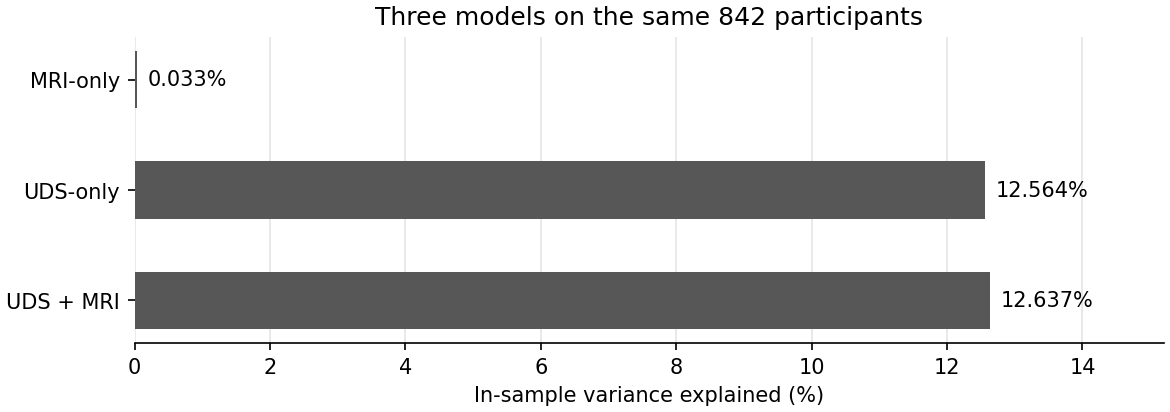

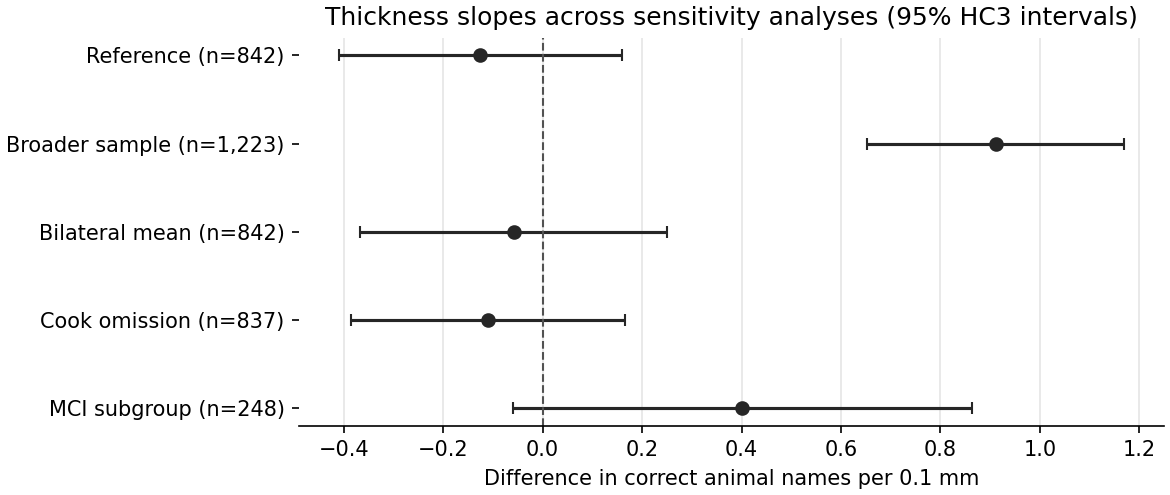

In [6]:
from src.phase1_figures import plt

for _, figure in build_figures(results):
    with BytesIO() as image:
        figure.savefig(image, format="png", dpi=150)
        display(Image(data=image.getvalue()))
    plt.close(figure)

## Interpretation and limits

Including this MRI measure gives us a demographic-adjusted estimate in correct responses per 0.1 mm and adds little in-sample fit. The broader eligibility rule changes the estimate most. Averaging the two sides or temporarily leaving out cases moves the reference estimate closer to zero. The bootstrap and HC3 intervals remain compatible with reference associations in either direction.

We know that all UDS-eligible people with normal cognition had usable MRI in the teaching extract. We have one supplied pair of records per person and lack the information needed to compare visit rules. The selection frame, scan quality, imputation and timing remain unknown. The report compares our sample, task and imaging measure with three original studies by Eastman et al., Vonk et al. and Grönholm-Nyman et al.